In [1]:
%load_ext autoreload
%autoreload 2

# Predictability characteristics of LMEs

In [127]:
import esm4ppe
import cartopy.crs as ccrs
import cartopy
import matplotlib.pyplot as plt
import geopandas as gpd
import xarray as xr

In [92]:
# Load climatological intpp
variable,frequency='intpp','monthly'
es = esm4ppe.esm4ppeObj(variable,frequency).add_control().climatology()

Opening static... static opened.
Ensemble present in zarr store... opening... ensemble opened.
control opened.
Opening climatology... climatology opened.


/home/graemem/.conda/envs/climpred/lib/python3.11/site-packages/xarray/conventions.py:448: SerializationWarning: variable 'thkcello' has multiple fill values {1e+20, 1e+20}, decoding all values to NaN.
  new_vars[k] = decode_cf_variable(
/home/graemem/.conda/envs/climpred/lib/python3.11/site-packages/xarray/conventions.py:448: SerializationWarning: variable 'volcello' has multiple fill values {1e+20, 1e+20}, decoding all values to NaN.
  new_vars[k] = decode_cf_variable(


In [153]:
# load LME polygons
rootdir = '/projects/SOCCOM/datasets/LargeMarineEcos/LME66/'
filename = 'LMEs66.shp'
df = gpd.read_file(rootdir+filename)
# Load masks
masks = esm4ppe.masks.get_masks('LME',es.static)

## Plot a global map of primary production with LMEs overlaid

In [94]:
X = es.static["geolon"]
Y = es.static["geolat"]
Z = es.control[variable].max("month")

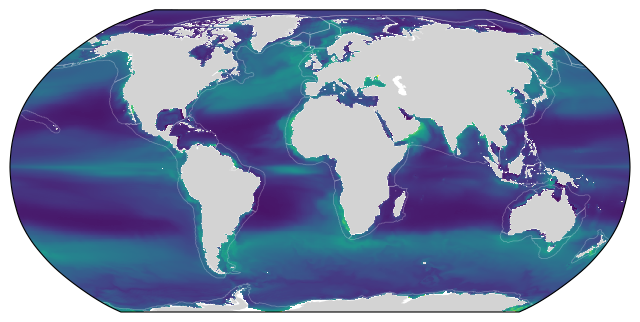

In [95]:
fig,ax = plt.subplots(figsize=(8,4),subplot_kw={'projection':ccrs.Robinson()})
ax.pcolormesh(X,Y,Z,transform=ccrs.PlateCarree())
ax.add_feature(cartopy.feature.LAND,facecolor='lightgrey')
for region,da in masks.items():
    ax.contour(X,Y,da.transpose(),levels=[0.5],colors='white',linewidths=0.5,transform=ccrs.PlateCarree(),alpha=0.3)

## Plot a map of a specific region

In [96]:
region = 'Benguela Current'
ds = es.control.where(masks[region]==1,drop=True)
static_region = es.static.sel({"xh":ds["xh"],"yh":ds["yh"]})

In [101]:
# get boundaries of region
buffer = 3 # set a buffer
lons,lats = (
    [static_region["geolon"].min().values-buffer,
     static_region["geolon"].max().values+buffer],
    [static_region["geolat"].min().values-buffer,
     static_region["geolat"].max().values+buffer]
)

In [102]:
import matplotlib.path as mpath
import numpy as np
def create_rectanglepathfromlonlatcorners(lons,lats,resolution=20):
    path = mpath.Path(
        list(zip(np.linspace(lons[0],lons[1], resolution), np.full(resolution, lats[1]))) + \
        list(zip(np.full(resolution, lons[1]), np.linspace(lats[1], lats[0], resolution))) + \
        list(zip(np.linspace(lons[1], lons[0], resolution), np.full(resolution, lats[0]))) + \
        list(zip(np.full(resolution, lons[0]), np.linspace(lats[0], lats[1], resolution)))
    )
    return path

In [103]:
path = create_rectanglepathfromlonlatcorners(lons,lats,20)

In [104]:
X = es.static["geolon"].values
Y = es.static["geolat"].values
Z = es.control[variable].max("month")

Text(0.5, 1.0, 'Benguela Current')

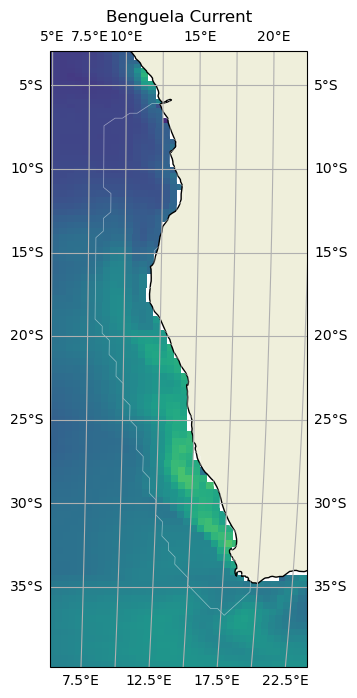

In [105]:
proj = ccrs.Robinson()
fig, ax = plt.subplots(figsize=(12, 8),
                       subplot_kw={'projection':proj})
ax.pcolormesh(X,Y,Z,transform=ccrs.PlateCarree())
ax.contour(X,Y,masks[region].transpose(),levels=[0.5],colors='white',linewidths=0.5,transform=ccrs.PlateCarree(),alpha=0.5)
# ax.set_boundary(path,transform=ccrs.PlateCarree())
ax.set_extent((lons[0],lons[1],lats[0],lats[1]))
ax.add_feature(cartopy.feature.LAND, zorder=1, edgecolor='k')
ax.gridlines(
    draw_labels=True, rotate_labels=False,
    x_inline=False, y_inline=False,
)
ax.set_title(region)

## Calculate total NPP associated with a selection of LMEs

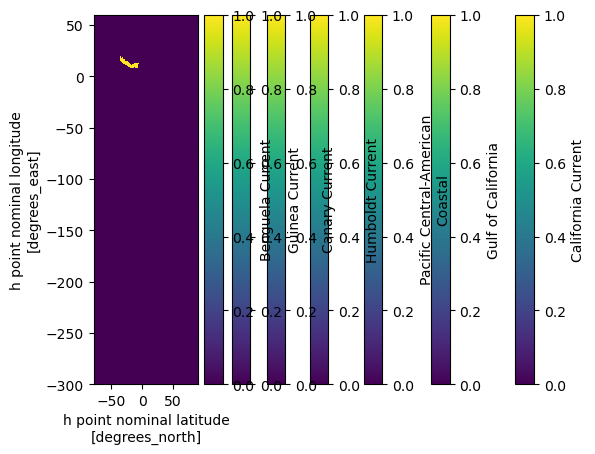

In [154]:
intppglobal = (es.control[variable]).weighted(static['areacello']).sum(["xh","yh"])
areaglobal = static['areacello'].sum(["xh","yh"])

LME_subset = ['California Current','Gulf of California','Pacific Central-American Coastal','Humboldt Current','Canary Current','Guinea Current','Benguela Current']
intppregion = xr.Dataset()
arearegion = xr.Dataset()
for i, (region,mask) in enumerate(masks[LME_subset].items()):
    intppregion[region] = (es.control[variable]*mask).weighted(static['areacello']).sum(["xh","yh"])
    arearegion[region] = (static['areacello']*mask).sum(["xh","yh"])
intppregionpercent = (intppregion/intppglobal)*100
arearegionpercent = (arearegion/areaglobal)*100
intppregionpercenttotal = intppregionpercent.to_array(dim='region').sum('region')

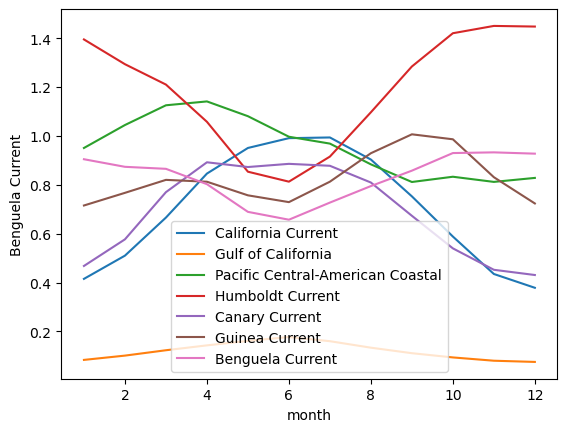

In [155]:
for name, array in intppregionpercent.items():
    array.plot(label=name)
plt.gca().legend()

In [156]:
for name, array in arearegionpercent.items():
    array.plot(label=name)
plt.gca().legend()

TypeError: No numeric data to plot.

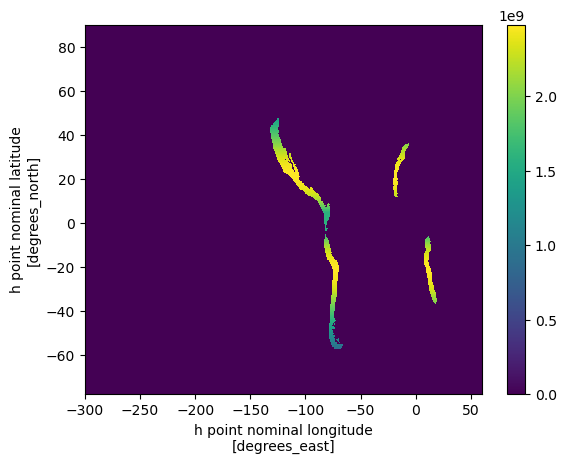

In [148]:
(static['areacello']*mask).plot()